# Highway Networks — Improving CIFAR-10 Accuracy

**Notebook:** `05_improved_highway_cifar10.ipynb`  
**Goal:** Move from a constant-width depth experiment to a stronger, multi-stage Highway CNN that can learn richer image representations.

Our strongest depth-experiment result was **66.06% validation accuracy** with 50 Highway blocks. That experiment investigated *trainability*, not maximum accuracy. Here we investigate *image classification quality*.

> **Important:** This is our own improved architecture, **not an exact reproduction** of the 2015 paper. Aiming for higher accuracy does not guarantee reaching 90%. We'll keep validation and test roles separate.

## 1. Architecture and research plan

Our earlier CNN kept 32 channels and spatial resolution $32\times32$ through every Highway block. The improved model uses **three stages**:

| Stage | Operation | Feature-map shape (without batch) |
|---|---|---|
| Input | CIFAR-10 RGB image | $3\times32\times32$ |
| Stem | $3\times3$ convolution + BN + ReLU | $32\times32\times32$ |
| Stage 1 | 2 Highway blocks | $32\times32\times32$ |
| Downsample 1 | stride-2 convolution + BN + ReLU | $64\times16\times16$ |
| Stage 2 | 2 Highway blocks | $64\times16\times16$ |
| Downsample 2 | stride-2 convolution + BN + ReLU | $128\times8\times8$ |
| Stage 3 | 2 Highway blocks | $128\times8\times8$ |
| Classifier | global average pooling, dropout, linear | 10 logits |

The block retains the Highway equation:

$$
\boxed{y=H(x)\odot T(x)+x\odot(1-T(x))}
$$

We use a convolution followed by batch normalization and ReLU for $H(x)$, and convolution followed by sigmoid for $T(x)$:

$$H(x)=\operatorname{ReLU}(\operatorname{BN}(\operatorname{Conv}_H(x)))$$
$$T(x)=\sigma(\operatorname{Conv}_T(x))$$

A negative gate bias initially favors carrying features forward. **Batch normalization is an experimental modification** to our previous layer, not a claim about the exact paper implementation. The channel-changing downsampling operations are separate from Highway blocks so the identity carry path always has matching dimensions.

## 2. Setup and reproducibility

Run from `notebooks/` or project root. Do not rerun the training cells from notebook 04.

In [1]:
from pathlib import Path
import sys

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import get_cifar10
from src.improved_model import count_parameters
from src.training import set_seed, run_epoch, train_model, load_checkpoint

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_ROOT)
print("Device:", device)
print("PyTorch:", torch.__version__)

Project: C:\Users\rbern\Desktop\DL\highway-networks
Device: cuda
PyTorch: 2.14.1+cu126


## 3. CIFAR-10: clean training/validation split

We reuse the **same split method** as in notebook 04: a `torch.randperm(50000, generator=torch.Generator().manual_seed(42))`, with the first 5,000 indices for validation and the remaining 45,000 for training.

- **Train:** crop + flip + normalization, 45,000 images.
- **Validation:** normalization only, 5,000 images. Used for checkpoint selection and model development.
- **Test:** normalization only, 10,000 images. Use after choosing the model.

The test set was already inspected in earlier notebooks, so this project as a whole cannot claim a completely untouched test set.

In [2]:
# Split, transforms and loaders live in src/data.py
data = get_cifar10(PROJECT_ROOT / "data", device, seed=SEED)

make_train_loader = data.make_train_loader
val_loader = data.val_loader
test_loader = data.test_loader
class_names = data.class_names

print("Train/val/test:", len(data.train_subset), len(data.val_subset), len(data.test_dataset))
print("Train/val/test batches:", len(make_train_loader()), len(val_loader), len(test_loader))

Train/val/test: 45000 5000 10000
Train/val/test batches: 352 40 79


## 4. Implement the improved Highway CNN

The block and the model are defined in `src/improved_model.py` so notebook 06 can reuse exactly the same architecture and load the saved checkpoints.

In [3]:
from src.improved_model import ImprovedHighwayBlock, ImprovedHighwayCNN, HIGHWAY_CONFIG

MODEL_CONFIG = HIGHWAY_CONFIG

def new_model():
    return ImprovedHighwayCNN(**MODEL_CONFIG).to(device)

model = new_model()
print("Trainable parameters:", f"{count_parameters(model):,}")

Trainable parameters: 870,250


## 5. Smoke test — before a full training run

Test shape, finite loss, and gradient flow on a tiny batch. This does **not** train the production model.

In [4]:
sample, labels = next(iter(val_loader))
sample = sample[:4].to(device)
labels = labels[:4].to(device)
model.train()
model.zero_grad(set_to_none=True)
logits = model(sample)
smoke_loss = nn.CrossEntropyLoss()(logits, labels)
smoke_loss.backward()
print("Logits:", logits.shape, "Loss:", round(smoke_loss.item(), 4))
print("First transform gradient exists:",
      model.stage1[0].transform[0].weight.grad is not None)
print("First gate gradient exists:", model.stage1[0].gate.weight.grad is not None)
assert logits.shape == (4, 10) and torch.isfinite(smoke_loss)
print("Smoke test passed")
# Fresh model for the actual training run, not the smoke-test model.
del model, sample, labels, logits, smoke_loss

Logits: torch.Size([4, 10]) Loss: 2.5063
First transform gradient exists: True
First gate gradient exists: True
Smoke test passed


## 6. Training configuration and metrics

We use `CrossEntropyLoss`, AdamW, and cosine annealing of the learning rate. The cosine schedule is an intentional experimental improvement over the fixed-rate depth experiments:

$$\eta_t = \eta_{\min} + \tfrac12(\eta_0-\eta_{\min})\left(1+\cos\left(\frac{\pi t}{T}\right)\right)$$

We track sample-weighted loss and accuracy for training and validation. **We select the best checkpoint using validation accuracy**, never test accuracy.

Start with `EPOCHS = 1` for a short end-to-end check; for a meaningful first run, reset to `20`. A result near 90% is a long-term goal, not guaranteed by this architecture.

In [ ]:
# AdamW + cosine annealing defaults, run_epoch and train_model live in src/training.py
from src.training import EPOCHS, LEARNING_RATE, MIN_LR, WEIGHT_DECAY, MAX_GRAD_NORM

print(f"Epochs {EPOCHS} | LR {LEARNING_RATE} -> {MIN_LR} | weight decay {WEIGHT_DECAY} | "
      f"grad clip {MAX_GRAD_NORM}")

## 7. Train and save checkpoints

The code saves **latest** (including optimizer and scheduler) and **best** checkpoints separately after every epoch. Rerunning this cell starts from scratch and overwrites this experiment’s checkpoints; use a different `RUN_NAME` for another experiment.

> The saved output below comes from the original run, before the code was moved into `src/`. The refactored code was verified to load the same checkpoint and reproduce the same validation predictions.

In [6]:
RUN_NAME = "improved_highway_v1"
checkpoint_dir = PROJECT_ROOT / "checkpoints" / "improved_highway"

history, best_path = train_model(
    ImprovedHighwayCNN, MODEL_CONFIG,
    make_train_loader, val_loader, device,
    checkpoint_dir, RUN_NAME, seed=SEED,
)

Epoch 01/20 | train loss 1.4451 acc 46.79% | val loss 1.0832 acc 61.74% | LR 0.001000 | best 61.74% (epoch 1)
Epoch 02/20 | train loss 0.9840 acc 64.63% | val loss 0.9351 acc 67.06% | LR 0.000994 | best 67.06% (epoch 2)
Epoch 03/20 | train loss 0.8075 acc 71.51% | val loss 0.8218 acc 71.86% | LR 0.000976 | best 71.86% (epoch 3)
Epoch 04/20 | train loss 0.6899 acc 75.96% | val loss 0.7004 acc 76.14% | LR 0.000946 | best 76.14% (epoch 4)
Epoch 05/20 | train loss 0.6052 acc 78.95% | val loss 0.5745 acc 80.22% | LR 0.000905 | best 80.22% (epoch 5)
Epoch 06/20 | train loss 0.5367 acc 81.53% | val loss 0.6135 acc 79.02% | LR 0.000855 | best 80.22% (epoch 5)
Epoch 07/20 | train loss 0.4894 acc 83.22% | val loss 0.5551 acc 81.34% | LR 0.000796 | best 81.34% (epoch 7)
Epoch 08/20 | train loss 0.4477 acc 84.58% | val loss 0.4812 acc 83.46% | LR 0.000730 | best 83.46% (epoch 8)
Epoch 09/20 | train loss 0.4080 acc 85.89% | val loss 0.4929 acc 83.20% | LR 0.000658 | best 83.46% (epoch 8)
Epoch 10/2

## 8. Visualize training and analyze the best validation checkpoint

Inspect the learning curves before changing hyperparameters. A large training-validation gap can indicate overfitting; a consistently high training loss can suggest an optimization problem.

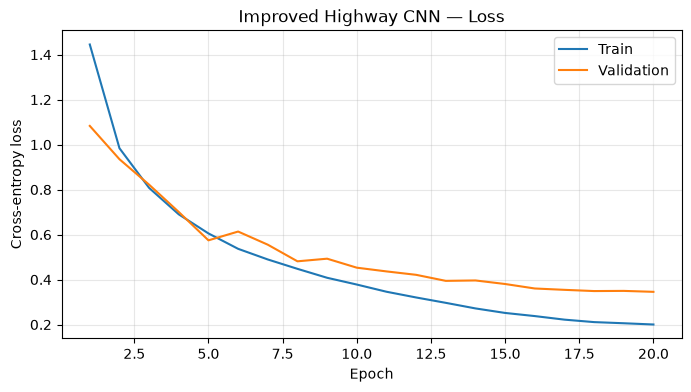

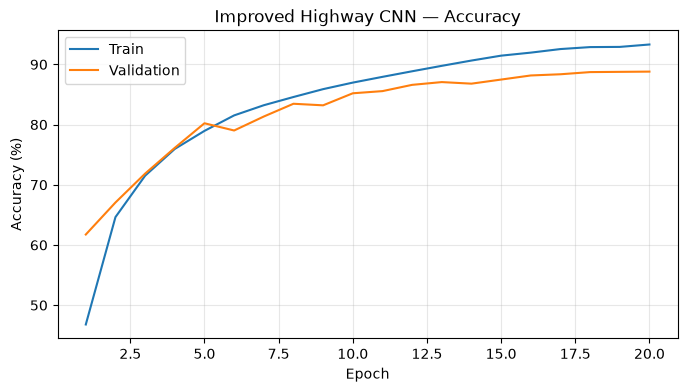

Best validation accuracy: 88.80%
Best epoch: 20
Final validation accuracy: 88.80%


In [7]:
epoch_numbers = list(range(1, len(history["train_loss"]) + 1))
plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, history["train_loss"], label="Train")
plt.plot(epoch_numbers, history["val_loss"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("Improved Highway CNN — Loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, history["train_accuracy"], label="Train")
plt.plot(epoch_numbers, history["val_accuracy"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)")
plt.title("Improved Highway CNN — Accuracy")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("Best validation accuracy:", f"{max(history['val_accuracy']):.2f}%")
print("Best epoch:", history["val_accuracy"].index(max(history["val_accuracy"]))+1)
print("Final validation accuracy:", f"{history['val_accuracy'][-1]:.2f}%")

## 9. Final evaluation (run only after model selection)

Reload the **best validation checkpoint**, then evaluate on the CIFAR-10 test set. Don't use this result to choose hyperparameters; tuning should continue on validation data. The test set was used during earlier project exploration, so interpret this as a project evaluation rather than a fully untouched benchmark.

In [8]:
from src.training import predict, per_class_accuracy

best_path = PROJECT_ROOT / "checkpoints" / "improved_highway" / "improved_highway_v1_best.pth"
selected_model, best_checkpoint = load_checkpoint(ImprovedHighwayCNN, best_path, device)

test_loss, test_acc = run_epoch(selected_model, test_loader, device)
print("Selected epoch:", best_checkpoint["epoch"])
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2f}%")

predictions, targets = predict(selected_model, test_loader, device)
for name, accuracy in zip(class_names, per_class_accuracy(predictions, targets)):
    print(f"{name:12s}: {accuracy:6.2f}%")

Selected epoch: 20
Test loss: 0.3803
Test accuracy: 88.07%
airplane    :  90.20%
automobile  :  94.00%
bird        :  83.30%
cat         :  77.50%
deer        :  88.20%
dog         :  80.90%
frog        :  91.30%
horse       :  88.70%
ship        :  94.30%
truck       :  92.30%



## 10. Results and Conclusions

### 10.1 Experimental Configuration

We trained an improved multi-stage Convolutional Highway Network on CIFAR-10.

| Configuration | Value |
|---|---|
| Training samples | 45,000 |
| Validation samples | 5,000 |
| Test samples | 10,000 |
| Trainable parameters | 870,250 |
| Training epochs | 20 |
| Initial learning rate | 0.001 |
| Training time | 18.5 minutes |
| Model selection | Best validation accuracy |

The improved architecture uses multiple convolutional feature stages, spatial downsampling, Highway Layers, and a learning-rate schedule.

### 10.2 Final Training Results

| Metric | Result |
|---|---:|
| Final training loss | 0.2003 |
| Final training accuracy | 93.30% |
| Best validation loss at selected epoch | 0.3456 |
| Best validation accuracy | **88.80%** |
| Best epoch | 20 |
| Test loss | 0.3803 |
| Test accuracy | **88.07%** |

The training-validation accuracy gap was:

$$
93.30\%-88.80\%=4.50\text{ percentage points}
$$

### 10.3 Per-Class Test Accuracy

| Class | Accuracy |
|---|---:|
| Airplane | 90.20% |
| Automobile | 94.00% |
| Bird | 83.30% |
| Cat | 77.50% |
| Deer | 88.20% |
| Dog | 80.90% |
| Frog | 91.30% |
| Horse | 88.70% |
| Ship | **94.30%** |
| Truck | 92.30% |

The best-performing class was **ship**, while the lowest accuracy was observed for **cat**.

### 10.4 Comparison With Earlier Experiments

| Experiment | Accuracy | Evaluation Set |
|---|---:|---|
| Initial Highway CNN | 55.79% | Test |
| 10-block Highway CNN | 63.92% | Validation |
| 50-block Highway CNN | 66.06% | Validation |
| Improved Highway CNN | **88.80%** | Validation |
| Improved Highway CNN | **88.07%** | Test |

The improved model significantly outperformed the earlier experimental architectures.

Compared with the initial Highway CNN test result:

$$
88.07\%-55.79\%=32.28\text{ percentage points}
$$

The improvement reflects multiple changes, including architecture, model capacity, training duration, and optimization settings.

### 10.5 Observations

1. Training accuracy increased from 46.79% to 93.30%.
2. Validation accuracy increased from 61.74% to 88.80%.
3. The model reached its best validation accuracy at the final epoch.
4. The final test accuracy of 88.07% was close to validation accuracy.
5. Classes such as ship and automobile achieved over 94% accuracy.
6. Animal categories, especially cat and dog, remained relatively challenging.
7. A multi-stage architecture was substantially more effective than our earlier constant-width Highway CNN.

### 10.6 Comparison With the Original Paper

The original Highway Networks paper reported CIFAR-10 test accuracies exceeding 90%, including 92.24% for one of its 19-layer models.

Our improved model reached 88.07% test accuracy.

The difference is:

$$
92.24\%-88.07\%=4.17\text{ percentage points}
$$

This is a contextual comparison rather than an exact reproduction because the architectures, preprocessing, model sizes, and training procedures differ.

### 10.7 Final Conclusion

We successfully trained an improved Convolutional Highway Network on CIFAR-10.

The model achieved:

$$
\boxed{\text{Validation accuracy}=88.80\%}
$$

$$
\boxed{\text{Test accuracy}=88.07\%}
$$

The experiment demonstrates that Highway Networks can be used in effective image classification architectures.

Our earlier depth experiments also showed that learned carry gates can assist optimization in deep networks, although extremely deep configurations remained sensitive to initialization and training stability.

**Final takeaway:** Highway Networks provide an adaptive mechanism for preserving and transforming information. Combining them with a stronger convolutional architecture and suitable training procedures enabled substantially higher classification accuracy in our experiments.
